# Introduction to Natural Language Processing: Assignment 2

In this exercise we'll practice features extraction using Tf-Idf and SpaCy as well as multiclass text classification using the word embedding technique.

- You can use built-in Python packages, spaCy, scikit-learn, Numpy and Pandas.
- Please comment your code
- Submissions are due Tuesdays at 23:59 AoE **only** on eCampus: **Assignmnets >> Student Submissions >> Assignment 2**

- Name the file aproppriately: "Assignment_2_\<Your_Name\>.ipynb" and submit only the Jupyter Notebook file.
- If you are working in a group of two, please have the names of both of the members in the file name.
- Please use relative path, your code should work on my computer if the Jupyter Notebook and the file are both in the same directory.

Example: file_name = bbc-news.csv, **DON'T use:** /Users/ComputerName/Username/Documents/.../bbc-news.csv

### Task 1 (2 points)

Write a function `extract_proper_nouns(my_file_name)` that takes a file name (my_file_name.txt) as input and returns a list containing all proper nouns with more than one token.

**Example:**

text = "Hong Kong and Japan are two countries in Asia and New York is the largest city in the world"

return = `["New York", "Hong Kong"]` **(Note: it should not return "Japan")**

In [1]:
import spacy

# Load the English language model
nlp = spacy.load("en_core_web_sm")


def extract_proper_nouns(my_file_name):
    # Create an empty list to store proper noun phrases
    # that contain at least 2 consecutive tokens
    several_token_propn = []

    # Open the text file and read its entire content
    with open(my_file_name, "r", encoding="utf-8") as file:
        text = file.read()

    # Process the text with spaCy to identify the Part-of-Speech (POS)
    # of each token (e.g. NOUN, PROPN, VERB, ADJ)
    doc = nlp(text)

    # Temporary list to collect consecutive proper nouns
    current_group = []

    # Loop through every token in the processed text
    for token in doc:

        # Check if the current token is a proper noun
        if token.pos_ == "PROPN":

            # If it is, add it to the current group
            current_group.append(token.text)

        else:
            # If the current token is NOT a proper noun,
            # we have reached the end of a consecutive proper noun group

            # Only keep groups containing at least 2 tokens
            if len(current_group) >= 2:

                # Combine the tokens into one phrase and add it to our results
                # Example: ["New", "York"] becomes "New York"
                several_token_propn.append(" ".join(current_group))

            # Reset the group so we can start collecting a new one
            current_group = []

    # IMPORTANT: Check the last group once the loop finishes.
    # Otherwise, a proper noun phrase at the very end of the text
    # would never be added to our results.
    if len(current_group) >= 2:
        several_token_propn.append(" ".join(current_group))

    # Return the list of proper noun phrases
    return several_token_propn


### Task 2 (3 points)

Write a function `common_lemma(my_file_name)` that takes a file name (my_file_name.txt) as input and returns a Python dictionary with lemmas as `key` and the `value` that should contain a list with both verbs and nouns sharing the same lemma.

**Examples:**

1.
text = "When users google for a word or any query, their system internally runs a pipeline in order to process what the person is querying."

return = `{"query": ["query", "querying"]}`

2.
text = I really loved the movie and show, the movie was showing reality but it showed sometimes nonesense!

return = `{"show": ["show", "showing", "showed"]}` **(Note: it should not return "movie" because both "movie"s are NOUN)**

In [2]:
import spacy
# Load the English language model
nlp = spacy.load("en_core_web_sm")


def common_lemma(my_file_name):
    # Dictionary to store original words grouped by their lemma
    tokens_with_common_lemma = {}

    # Dictionary to track the POS categories associated with each lemma
    lemma_pos = {}

    # Read the text file
    with open(my_file_name, "r", encoding="utf-8") as file:
        text = file.read()

    # Process the text using spaCy
    doc = nlp(text)

    # Iterate through all tokens in the document
    for token in doc:

        # We only care about nouns and verbs
        if token.pos_ in ["NOUN", "VERB"]:

            # Get the lemma of the current token
            lemma = token.lemma_.lower()

            # If this lemma hasn't been encountered before,
            # create an empty list and an empty set for it
            if lemma not in tokens_with_common_lemma:
                tokens_with_common_lemma[lemma] = []
                lemma_pos[lemma] = set()

            # Add the original word to the corresponding lemma
            # We keep duplicates because every occurrence matters
            tokens_with_common_lemma[lemma].append(token.text)

            # Track the grammatical category of this token
            lemma_pos[lemma].add(token.pos_)

    # Filter the dictionary:
    # Keep only lemmas that have BOTH a noun and a verb
    tokens_with_common_lemma = {
        lemma: words
        for lemma, words in tokens_with_common_lemma.items()
        if {"NOUN", "VERB"}.issubset(lemma_pos[lemma])
    }

    # Return the filtered dictionary
    return tokens_with_common_lemma


In [6]:
import os

# Show the current working directory
print(os.getcwd())

# Show the files in that directory
print(os.listdir())

c:\Uni\WiSe2627\Intro to NLP\Assignments\Assignment 1\NLPAssigments\Assignment 2
['.venv', 'bbc-news(1).csv', 'Intro2NLP_Assignment_2_Your_Name(2).ipynb']


### Task 3 (1 point)

Load the data `bbc-text.csv`; This datata consists of 2225 documents from the BBC news website corresponding to stories from 2004-2005.

In [8]:
import pandas as pd

# Load the CSV file
df = pd.read_csv("bbc-news(1).csv")

### Task 4 (1 point)

Show how many articles we have for each topical area (class label) in the dataset using a plot.

category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


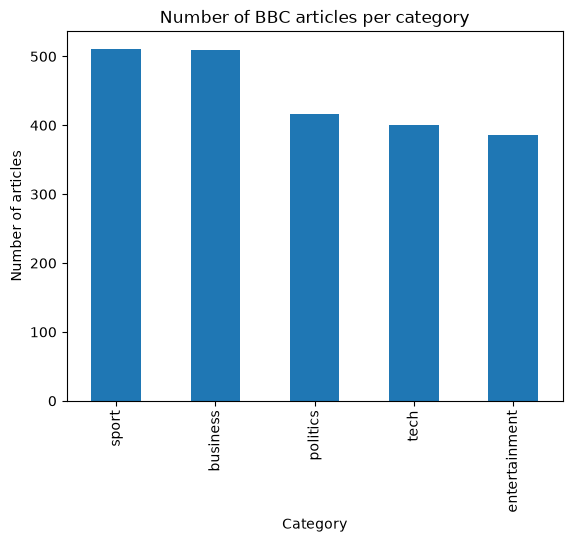

In [9]:
import matplotlib.pyplot as plt

# Count the number of articles in each category
category_counts = df["category"].value_counts()

print(category_counts)
# Create a bar plot
category_counts.plot(kind="bar")

# Add labels and title
plt.xlabel("Category")
plt.ylabel("Number of articles")
plt.title("Number of BBC articles per category")

# Display the plot
plt.show()

### Task 5 (2 point)

Preprocessing: Define two following functions and apply them to the dataset:
1. Remove punctuation
2. Remove any numbers

In [12]:
import re

def remove_punctuation(corpus):
    # Remove punctuation characters
    cleaned_corpus = corpus.apply(lambda text: re.sub(r'[^\w\s]', '', text))

    return cleaned_corpus

def remove_numbers(corpus):
    # Remove all digits (0-9)
    cleaned_corpus = corpus.apply(lambda text: re.sub(r'\d+', '', text))

    return cleaned_corpus


# Remove punctuation
df["text"] = remove_punctuation(df["text"])

# Remove numbers
df["text"] = remove_numbers(df["text"])

print(df["text"].head())

0    tv future in the hands of viewers with home th...
1    worldcom boss  left books alone  former worldc...
2    tigers wary of farrell  gamble  leicester say ...
3    yeading face newcastle in fa cup premiership s...
4    ocean s twelve raids box office ocean s twelve...
Name: text, dtype: str


### Task 6.1 (1 points)

Split the data into training and test set (70% and 30%) using scikit-learn, shuffle it, and set the `seed=101 (random_state)`.

**NOTE:** If working with this dataset is not computationaly possible for you, you can work only with a subset of the dataset (i.e., the first 1000 rows) and use only the first 150 tokens for each article. You should point this out in your code.

In [13]:
from sklearn.model_selection import train_test_split

# Define features (X) and labels (y)
X = df["text"]
y = df["category"]

# Split into training (70%) and test (30%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=101,
    shuffle=True
)

### Task 6.2 (3 points)

### **Training models on TF-IDF vectors:**

a) Convert each article in your data splits to a vector representation using the tf-idf-vectorizer.

b) Using the vectors from the previous step, train the `MLPClassifier` and another model of your choice from the scikit-learn library.

c) Test both of your models on the test set from Task 6.1.

In [16]:
#a) Convert each article in your data splits to a vector representation using the tf-idf-vectorizer.


from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer()

# Learn the vocabulary and IDF values from the training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform the test data using the same vocabulary and IDF values
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Test data shape:", X_test_tfidf.shape)

# Display the first 20 words in the vocabulary
print(tfidf_vectorizer.get_feature_names_out()[:20])

# Get the first article's TF-IDF vector
first_article = X_train_tfidf[0].toarray()[0]

# Get the vocabulary
words = tfidf_vectorizer.get_feature_names_out()

# Print only words that appear in the article
for word, value in zip(words, first_article):
    if value > 0:
        print(word, round(value, 3))

Training data shape: (1557, 26129)
Test data shape: (668, 26129)
['aaa' 'aaas' 'aac' 'aadc' 'aaliyah' 'aaltra' 'aamir' 'aan' 'aara'
 'aarhus' 'aaron' 'abacus' 'abandon' 'abandoned' 'abandoning'
 'abandonment' 'abate' 'abatement' 'abating' 'abba']
about 0.066
academy 0.13
according 0.027
actually 0.039
also 0.014
although 0.029
amadeus 0.071
among 0.03
and 0.074
animation 0.058
are 0.026
as 0.024
at 0.034
attendance 0.059
attracted 0.05
audience 0.081
aviator 0.047
award 0.036
awards 0.14
based 0.033
beat 0.035
been 0.028
before 0.021
best 0.078
bestowing 0.071
between 0.024
biggest 0.091
bit 0.037
blockbusters 0.124
bn 0.054
board 0.037
box 0.234
bruce 0.049
but 0.024
by 0.023
category 0.041
ceremony 0.122
choice 0.037
christ 0.058
clutch 0.057
combined 0.047
compared 0.039
compete 0.042
concern 0.081
davis 0.043
dergarabedian 0.062
director 0.028
distribution 0.048
do 0.042
does 0.06
don 0.027
each 0.031
equate 0.067
equated 0.071
eventually 0.043
executive 0.03
exhibitor 0.061
eyebal

In [17]:
#b) Using the vectors from the previous step, train the `MLPClassifier` and another model of your choice from the scikit-learn library.

# Import the models
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

# Create the MLP model
mlp = MLPClassifier(random_state=101)

# Train the model
mlp.fit(X_train_tfidf, y_train)

# Create the LinearSVM model
svm = LinearSVC(random_state=101)

# Train the model
svm.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",101
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically ad

In [19]:
#c)

# Predict categories using the MLPClassifier
y_pred_mlp = mlp.predict(X_test_tfidf)

# Predict categories using LinearSVC
y_pred_svm = svm.predict(X_test_tfidf)

# Display the first 10 actual and predicted categories
print("Actual categories:")
print(y_test.head(10).values)

print("\nMLP predictions:")
print(y_pred_mlp[:10])

print("\nLinearSVC predictions:")
print(y_pred_svm[:10])

Actual categories:
<StringArray>
[     'business',      'politics', 'entertainment',          'tech',
      'politics',      'business',      'business', 'entertainment',
          'tech',          'tech']
Length: 10, dtype: str

MLP predictions:
['business' 'politics' 'business' 'tech' 'politics' 'business' 'business'
 'entertainment' 'tech' 'tech']

LinearSVC predictions:
['business' 'politics' 'politics' 'tech' 'politics' 'business' 'business'
 'entertainment' 'tech' 'tech']


### Task 6.3 (3 points)

### **Training models on SpaCy model vector representation:**

a) Convert each article in your data splits to a vector representation using the pre-trained spaCy model. (**Hint:** It should be stored as an array)

b) Using the vectors from the previous step, train the `MLPClassifier` and another model of your choice from the scikit-learn library.

c) Test both of your models on the test set from Task 6.1.

In [ ]:
#a)
import spacy
import numpy as np

# Load the pre-trained medium English model
nlp = spacy.load("en_core_web_md")

# Convert training articles into spaCy vectors
X_train_spacy = np.array([nlp(text).vector for text in X_train])

# Convert test articles into spaCy vectors
X_test_spacy = np.array([nlp(text).vector for text in X_test])

print("Training array shape:", X_train_spacy.shape)
print("Test array shape:", X_test_spacy.shape)

# Display the vector of the first training article
print(X_train_spacy[0])

Training array shape: (1557, 300)
Test array shape: (668, 300)
[-6.45808399e-01  1.78125218e-01 -4.50886339e-02 -3.03627793e-02
 -4.61560749e-02 -2.07518172e-02  2.22022682e-02 -1.04450181e-01
  2.75336560e-02  1.68151748e+00 -1.77382320e-01 -5.25639206e-02
 -6.63577300e-03  1.11659281e-02 -2.83893868e-02 -3.55107896e-02
 -7.81285688e-02  9.10862863e-01 -1.36647359e-01 -3.35994479e-03
 -6.31076545e-02  1.65991038e-02  1.29625632e-03 -2.20935524e-01
 -2.83244029e-02 -8.18450898e-02 -5.28047606e-02 -5.24346009e-02
 -4.21274118e-02  4.79913549e-03 -7.71304742e-02  4.85663004e-02
 -1.02827465e-02 -8.53921007e-03  8.66130814e-02  1.25538066e-01
 -1.53095663e-01  2.78188195e-02 -6.54547885e-02 -7.20617687e-03
  6.54814988e-02  1.10965297e-02  6.73518032e-02  6.32618442e-02
  9.62575227e-02 -9.46862996e-02 -4.72714640e-02 -1.60166919e-02
 -3.57403979e-02  2.91847456e-02 -4.64635454e-02  1.10244542e-01
  7.09568709e-02 -8.09886381e-02  2.42075231e-02 -3.91784422e-02
 -3.69049720e-02 -6.1696067

In [ ]:
#b)

from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

# Create the MLP model
mlp_spacy = MLPClassifier(random_state=101)

# Train the model using spaCy vectors
mlp_spacy.fit(X_train_spacy, y_train);

# Create the LinearSVC model
svm_spacy = LinearSVC(random_state=101)

# Train the model using spaCy vectors
svm_spacy.fit(X_train_spacy, y_train);

print("MLP training completed:", mlp_spacy.n_iter_)
print("LinearSVC training completed:", svm_spacy.classes_)

c:\Uni\WiSe2627\Intro to NLP\Assignments\Assignment 1\NLPAssigments\Assignment 2\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP training completed: 200
LinearSVC training completed: ['business' 'entertainment' 'politics' 'sport' 'tech']


In [24]:
#c)

# Predict the categories of the test articles using the MLP model
y_pred_mlp_spacy = mlp_spacy.predict(X_test_spacy)

# Predict the categories of the test articles using the LinearSVC model
y_pred_svm_spacy = svm_spacy.predict(X_test_spacy)

# Display the first 10 actual and predicted categories
print("Actual categories:")
print(y_test.head(10).tolist())

print("\nMLP predictions:")
print(y_pred_mlp_spacy[:10])

print("\nLinearSVC predictions:")
print(y_pred_svm_spacy[:10])

Actual categories:
['business', 'politics', 'entertainment', 'tech', 'politics', 'business', 'business', 'entertainment', 'tech', 'tech']

MLP predictions:
['business' 'politics' 'politics' 'tech' 'politics' 'business' 'business'
 'entertainment' 'business' 'tech']

LinearSVC predictions:
['business' 'politics' 'entertainment' 'tech' 'politics' 'business'
 'business' 'entertainment' 'business' 'tech']


### Task 7 (4 points)

Using the predictions from the four classifiers, evaluate the models and report accuracy, recall, precision, f1 scores and confusion matrix for each of them. (**Hint:** You should build a confusion matrix for multi-class classification)

In [25]:
#import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# Store all models and their predictions
models = {
    "MLP (TF-IDF)": y_pred_mlp,
    "LinearSVC (TF-IDF)": y_pred_svm,
    "MLP (spaCy)": y_pred_mlp_spacy,
    "LinearSVC (spaCy)": y_pred_svm_spacy
}

# Calculate evaluation metrics for each model
for model_name, predictions in models.items():

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, average="macro"))
    print("Recall:", recall_score(y_test, predictions, average="macro"))
    print("F1-score:", f1_score(y_test, predictions, average="macro"))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))


MLP (TF-IDF)
Accuracy: 0.9835329341317365
Precision: 0.9835588007405514
Recall: 0.9826765365103738
F1-score: 0.9830723888755

Confusion Matrix:
[[153   0   1   0   1]
 [  2 113   2   0   0]
 [  0   0 121   1   0]
 [  1   0   0 152   0]
 [  0   2   0   1 118]]

LinearSVC (TF-IDF)
Accuracy: 0.9835329341317365
Precision: 0.9829243703865131
Recall: 0.9834581856204686
F1-score: 0.9831504929479319

Confusion Matrix:
[[151   0   2   1   1]
 [  0 114   2   0   1]
 [  1   0 121   0   0]
 [  1   0   0 152   0]
 [  0   2   0   0 119]]

MLP (spaCy)
Accuracy: 0.937125748502994
Precision: 0.9370242135096916
Recall: 0.9374346216426208
F1-score: 0.9364595588907534

Confusion Matrix:
[[139   1  12   0   3]
 [  0 110   2   3   2]
 [  3   1 117   1   0]
 [  1   0   2 149   1]
 [  3   3   3   1 111]]

LinearSVC (spaCy)
Accuracy: 0.9461077844311377
Precision: 0.9452777424268802
Recall: 0.9445889424582757
F1-score: 0.9444494027392132

Confusion Matrix:
[[143   0  10   0   2]
 [  0 111   1   3   2]
 [  4   